# Detección de registros inusuales de sensores

![SENATI](../../04_RECURSOS/logo_senati.png)

**Actividad:** desarrollar una solución de aprendizaje no supervisado.  
**Dificultad:** intermedia, similar a las prácticas guiadas.  
**Datos:** simulados para clase.

## Situación de trabajo

Encontrar lecturas poco habituales de un sensor sin concluir automáticamente que hay una avería.

**Archivo:** `datos_sensores.csv`  
**Algoritmo sugerido:** Isolation Forest

En este caso no encontrarás el programa terminado. El objetivo es que repitas la metodología de los ejemplos resueltos y expliques tus decisiones.

**Trabajo desarrollado por:** COCA CCORPA LORENA ABIGAIL  
**Institución:** SENATI · 2026  
**Actividad:** Detección de registros inusuales de sensores  
**Nota:** Los datos suministrados por el taller son simulados; los resultados y pruebas son cálculos realizados sobre esos CSV.

## Parte A. Leer el CSV y elegir los datos

Completa el código. Empieza mostrando cinco filas y verificando las columnas de entrenamiento.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza la lectura, entrenamiento y explicación del reto. Se conserva el enunciado original y el código se ejecuta en orden.</div>

In [1]:
from pathlib import Path
import pandas as pd

ruta = Path('datos_sensores.csv')
if not ruta.exists():
    ruta = Path('03_RETOS_ESTUDIANTES/RETO_02_SENSORES/datos_sensores.csv')

datos = pd.read_csv(ruta)
display(datos.head())

# TODO: elegir las columnas numéricas que se utilizarán.
columnas = ['temperatura_c', 'vibracion_mm_s', 'corriente_a']
X = datos[columnas]
print("Registros:", len(X))

,codigo_lectura,temperatura_c,vibracion_mm_s,corriente_a
0,SEN001,48.4,2.81,5.94
1,SEN002,42.8,1.52,4.86
2,SEN003,42.1,2.14,6.33
3,SEN004,39.9,3.00,7.11
4,SEN005,34.5,2.80,3.67


Registros: 110


## Parte B. Entrenar y explicar

1. Crea el algoritmo recomendado.
2. Cuando corresponda, utiliza `StandardScaler`.
3. Entrena con `fit_predict()`.
4. Agrega la columna de grupo/alerta.
5. Muestra el número de registros por resultado.

Regresa al Proyecto 02 para agrupar o al Proyecto 04 para detectar registros poco habituales. Toma esos cuadernos como ejemplos, pero escribe tú la solución.

Resultados: {-1: 10, 1: 100}
Valores medios por resultado:
           temperatura_c  vibracion_mm_s  corriente_a
resultado                                            
-1                 56.43            3.68         8.69
 1                 39.71            2.56         6.07


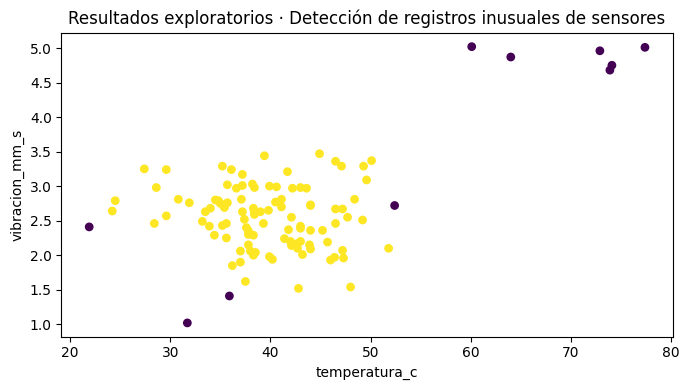

Nuevo caso de prueba: 1


In [2]:
# Entrenamiento reproducible: Detección de registros inusuales de sensores
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
CARACTERISTICAS = ['temperatura_c', 'vibracion_mm_s', 'corriente_a']
X = datos[CARACTERISTICAS]
escalador = StandardScaler()
X_escalada = escalador.fit_transform(X)
modelo = IsolationForest(n_estimators=150,contamination=0.09,random_state=42)
resultado = modelo.fit_predict(X_escalada)
datos['resultado'] = resultado
print('Resultados:',datos['resultado'].value_counts().sort_index().to_dict())
print('Valores medios por resultado:')
print(datos.groupby('resultado')[CARACTERISTICAS].mean().round(2))
joblib.dump({'modelo':modelo,'escalador':escalador,'columnas':CARACTERISTICAS,'algoritmo':'isolation'}, 'modelo_entrenado.joblib')
datos.to_csv('resultados.csv',index=False)
plt.figure(figsize=(7,4))
plt.scatter(datos[CARACTERISTICAS[0]],datos[CARACTERISTICAS[1]],c=resultado,cmap='viridis',s=28)
plt.xlabel(CARACTERISTICAS[0]);plt.ylabel(CARACTERISTICAS[1]);plt.title('Resultados exploratorios · '+ 'Detección de registros inusuales de sensores')
plt.tight_layout();plt.savefig('grafico_resultados.png',dpi=135);plt.show()
print('Nuevo caso de prueba:',modelo.predict(escalador.transform(X.iloc[[0]]))[0])


## Parte C. Aplicación y entrega

Crea `entrenar.py`, `app.py`, `templates/index.html` y `static/estilos.css`. La aplicación recibirá entradas numéricas en un formulario y mostrará el resultado del algoritmo, sin JavaScript.

### Evidencias

- CSV leído con Pandas.
- Tabla y gráfico con resultados.
- Una predicción nueva demostrada y explicada.
- Pantalla del formulario funcionando.
- Dos observaciones sobre las limitaciones del resultado.

### Preguntas para sustentar

1. ¿Por qué el problema es no supervisado?
2. ¿Por qué elegiste esas columnas?
3. ¿Por qué el algoritmo necesita (o no) normalizar los datos?
4. ¿Qué significa exactamente el resultado que muestra tu formulario?
5. ¿Qué pasaría si cambias uno de los valores ingresados?

**Rúbrica sugerida /20:** lectura de datos 4, preparación 4, algoritmo 5, formulario 4, explicación 3.

### Respuestas cortas

1. **¿Por qué no supervisado?** No hay etiqueta previa de sensor correcto o defectuoso.
2. **¿Por qué esas columnas?** Describen las lecturas disponibles para compararlas.
3. **¿Se normalizan?** Sí; ayuda a comparar variables, aunque Isolation Forest no depende de distancias como K-Means.
4. **¿Qué muestra la web?** Una alerta de lectura habitual o poco habitual.
5. **¿Qué ocurre si cambian los valores?** La alerta puede cambiar; no significa avería segura.

### Interpretación de pruebas y límites del algoritmo

In [3]:
paquete=joblib.load('modelo_entrenado.joblib')
filas=datos[CARACTERISTICAS].iloc[:2].copy()
filas['prediccion']=paquete['modelo'].predict(paquete['escalador'].transform(filas))
print(filas.to_string(index=False))

 temperatura_c  vibracion_mm_s  corriente_a  prediccion
          48.4            2.81         5.94           1
          42.8            1.52         4.86           1


**Isolation Forest:** La salida `-1` indica una observación poco habitual según el modelo y los datos educativos, no un error, avería ni peligro confirmado. Verifica esos casos antes de concluir. El escalador utilizado al predecir es **exactamente el entrenado**; estos CSV son simulados.